In [1]:
import numpy, pandas, sklearn, xgboost, torch, shap
print(numpy.__version__, pandas.__version__, sklearn.__version__)
print(xgboost.__version__, torch.__version__, shap.__version__)

2.2.1 2.2.3 1.9.1
3.4.1 2.14.1+cpu 0.53.0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

raw = "../data/raw/"
cols = ["engine", "cycle"] + [f"op{i}" for i in range(1, 4)] + [f"s{i}" for i in range(1, 22)]

train = pd.read_csv(raw + "train_FD001.txt", sep=r"\s+", header=None, names=cols)
test  = pd.read_csv(raw + "test_FD001.txt",  sep=r"\s+", header=None, names=cols)
rul_test = pd.read_csv(raw + "RUL_FD001.txt", header=None, names=["RUL"])

# RUL label for train: cycles left until the engine's last cycle
train["RUL"] = train.groupby("engine")["cycle"].transform("max") - train["cycle"]

print(train.shape, test.shape, rul_test.shape)
print("Train engines:", train.engine.nunique(), "| Test engines:", test.engine.nunique())
train.head()

(20631, 27) (13096, 26) (100, 1)
Train engines: 100 | Test engines: 100


,engine,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [3]:
sensors = [f"s{i}" for i in range(1, 22)]
stats = train[sensors].describe().T[["mean", "std", "min", "max"]]
print(stats)
print("\nConstant sensors:", list(stats[stats["std"] < 1e-6].index))

            mean           std        min        max
s1    518.670000  0.000000e+00   518.6700   518.6700
s2    642.680934  5.000533e-01   641.2100   644.5300
s3   1590.523119  6.131150e+00  1571.0400  1616.9100
s4   1408.933782  9.000605e+00  1382.2500  1441.4900
s5     14.620000  1.776400e-15    14.6200    14.6200
s6     21.609803  1.388985e-03    21.6000    21.6100
s7    553.367711  8.850923e-01   549.8500   556.0600
s8   2388.096652  7.098548e-02  2387.9000  2388.5600
s9   9065.242941  2.208288e+01  9021.7300  9244.5900
s10     1.300000  0.000000e+00     1.3000     1.3000
s11    47.541168  2.670874e-01    46.8500    48.5300
s12   521.413470  7.375534e-01   518.6900   523.3800
s13  2388.096152  7.191892e-02  2387.8800  2388.5600
s14  8143.752722  1.907618e+01  8099.9400  8293.7200
s15     8.442146  3.750504e-02     8.3249     8.5848
s16     0.030000  1.387812e-17     0.0300     0.0300
s17   393.210654  1.548763e+00   388.0000   400.0000
s18  2388.000000  0.000000e+00  2388.0000  238

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# 1. Keep useful sensors
drop_cols = ["s1", "s5", "s10", "s16", "s18", "s19"]
features = [s for s in sensors if s not in drop_cols]
print(len(features), "features:", features)

# 2. Cap RUL (early life is "healthy", exact RUL is unknowable)
CAP = 125
train["RUL_cap"] = train["RUL"].clip(upper=CAP)

# 3. Split BY ENGINE (never by row)
engines = train["engine"].unique()
tr_eng, val_eng = train_test_split(engines, test_size=0.2, random_state=42)

# 4. Scale: fit on train engines only
scaler = MinMaxScaler().fit(train.loc[train.engine.isin(tr_eng), features])
train_s, test_s = train.copy(), test.copy()
train_s[features] = scaler.transform(train[features])
test_s[features] = scaler.transform(test[features])

# 5. Sliding windows
W = 30
def make_windows(df, feats, W, target="RUL_cap"):
    X, y = [], []
    for _, g in df.groupby("engine"):
        arr, rul = g[feats].values, g[target].values
        for i in range(len(g) - W + 1):
            X.append(arr[i:i + W])
            y.append(rul[i + W - 1])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

X_tr, y_tr = make_windows(train_s[train_s.engine.isin(tr_eng)], features, W)
X_val, y_val = make_windows(train_s[train_s.engine.isin(val_eng)], features, W)

# 6. Test: ONE window per engine (its last 30 cycles), true RUL from file
X_test = np.array([g[features].values[-W:] for _, g in test_s.groupby("engine")], dtype=np.float32)
y_test = rul_test["RUL"].values.astype(np.float32)

print("train:", X_tr.shape, y_tr.shape)
print("val:  ", X_val.shape, y_val.shape)
print("test: ", X_test.shape, y_test.shape)

# 7. Save for the model notebooks
np.savez("../data/processed/fd001_windows.npz",
         X_tr=X_tr, y_tr=y_tr, X_val=X_val, y_val=y_val,
         X_test=X_test, y_test=y_test, features=np.array(features))

15 features: ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
train: (14241, 30, 15) (14241,)
val:   (3490, 30, 15) (3490,)
test:  (100, 30, 15) (100,)


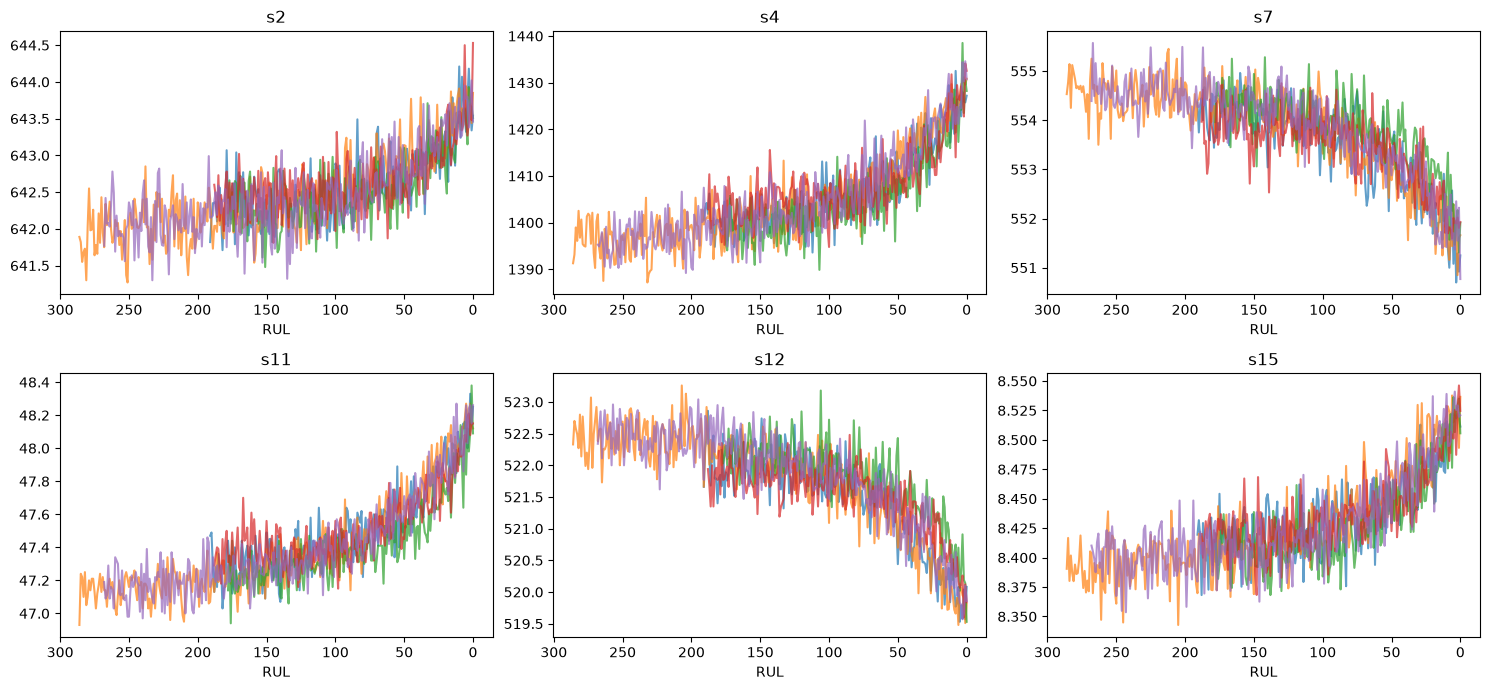

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, s in zip(axes.ravel(), ["s2", "s4", "s7", "s11", "s12", "s15"]):
    for eng in [1, 2, 3, 4, 5]:
        d = train[train.engine == eng]
        ax.plot(d["RUL"], d[s], alpha=0.7)
    ax.set_title(s)
    ax.invert_xaxis()
    ax.set_xlabel("RUL")
plt.tight_layout()
plt.show()